# The goat problem

A goat is tethered at the origin with a rope of length $r$. Its pen is the unit circle centred at $(0, 1)$, so the pen has area $\pi$. How long must the rope be for the goat to reach exactly half of the pen?

The reachable region is the intersection of two circles: radius $r$ centred at $(0,0)$ and radius $1$ centred at $(0,1)$, with centre distance $d=1$. The lens area is

$$
A(r) = r^2\arccos\!\left(\frac{d^2+r^2-1}{2dr}\right)
     + \arccos\!\left(\frac{d^2+1-r^2}{2d}\right)
     - \frac12\sqrt{(-d+r+1)(d+r-1)(d-r+1)(d+r+1)}.
$$

I solve $A(r)=\pi/2$ with Brent's method instead of differentiating under the integral sign.


In [1]:
import numpy as np
from scipy.optimize import brentq


def overlap_area(r, radius_pen=1.0, distance=1.0):
    """Area shared by a circle of radius r and the pen circle."""
    if r <= 0:
        return 0.0
    if r >= radius_pen + distance:          # goat covers the whole pen
        return np.pi * radius_pen**2
    if r <= abs(radius_pen - distance):     # goat stays inside the pen
        return np.pi * r**2

    a1 = r**2 * np.arccos((distance**2 + r**2 - radius_pen**2) / (2 * distance * r))
    a2 = radius_pen**2 * np.arccos(
        (distance**2 + radius_pen**2 - r**2) / (2 * distance * radius_pen))
    a3 = 0.5 * np.sqrt(
        (-distance + r + radius_pen) * (distance + r - radius_pen)
        * (distance - r + radius_pen) * (distance + r + radius_pen))
    return a1 + a2 - a3


target = np.pi / 2
rope_length = brentq(lambda r: overlap_area(r) - target, 1e-6, 2.0)
print(f"rope length: {rope_length:.10f}")
print(f"reachable area: {overlap_area(rope_length):.10f}")
print(f"half the pen area: {target:.10f}")


rope length: 1.1587284730
reachable area: 1.5707963268
half the pen area: 1.5707963268


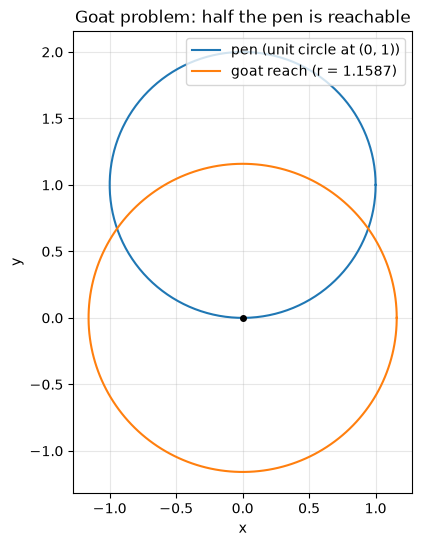

In [2]:
import matplotlib.pyplot as plt

theta = np.linspace(0, 2 * np.pi, 400)
pen_x, pen_y = np.cos(theta), 1 + np.sin(theta)
goat_x, goat_y = rope_length * np.cos(theta), rope_length * np.sin(theta)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(pen_x, pen_y, label="pen (unit circle at (0, 1))")
ax.plot(goat_x, goat_y, label=f"goat reach (r = {rope_length:.4f})")
ax.plot(0, 0, "ko", ms=4)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Goat problem: half the pen is reachable")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.show()


In [3]:
# Monte Carlo cross-check: sample the pen's bounding box and count the overlap.
rng = np.random.default_rng(2024)
num_samples = 1_000_000
x = rng.uniform(-1, 1, num_samples)
y = rng.uniform(0, 2, num_samples)
in_pen = x**2 + (y - 1)**2 <= 1
in_reach = x**2 + y**2 <= rope_length**2

monte_carlo_area = in_reach[in_pen].mean() * np.pi
print(f"Monte Carlo area: {monte_carlo_area:.4f}")
print(f"formula area:     {overlap_area(rope_length):.4f}")


Monte Carlo area: 1.5716
formula area:     1.5708


## Result

The rope must be about **1.1587** units long. The Monte Carlo estimate agrees with the closed-form lens area to within its sampling error, which is a useful check on both the geometry and the root finder.
